# Diffractive Propagation Method by a Pseudo-Spectral Approach

Simulation of a gaussian beam propagating through an optical element.

### 1.- Define the spatial grid $(x, y)$ and the corresponding spatial frequency grid $(k_x, k_y)$ needed for the Fourier-domain implementation of the BPM.

The beam propagation method solves the wave equation by an iterative process along the propagation axis $z$. We'll start by defining the 2D grid $(x,y)$ and the corresponding spatial frequencies $(k_x, k_y)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Defining the physical parameters as signalized in the document.
lam = 1.03e-6 # Wavelength (m)
k0 = 2 * np.pi / lam # Wave number in air
w0 = 50e-6
f = 10e-3 # focal length
Z_max = 30e-3

# Numerical grid parameters
N = 512 # Grid points
L = 1.5e-3 # Window size (m)
dx = L / N
dy = L / N

# Spatial coordinates
x = (np.arange(N) - N//2) * dx
y = (np.arange(N) - N//2) * dy
X, Y = np.meshgrid(x, y)

# Spatial frequency coordinates
fx = np.fft.fftfreq(N, dx)
fy = np.fft.fftfreq(N, dy)
Kx, Ky = np.meshgrid(2 * np.pi * fx, 2 * np.pi * fy)

### 2.- Generate the initial Gaussian field Gau_ini$(x, y)$ at $z = 0$.

The electric field profile is given by:

$$\psi(x,y,0) = \frac{1}{\omega_0\sqrt{\pi}}\exp\left(-\frac{x^2+y^2}{\omega_0^2}\right)$$

In [2]:
psi_ini = (1 / w0 * np.sqrt(np.pi)) * np.exp(-(X**2 + Y**2) / w0**2)

### 3.- Apply the Thin-Lens Phase Mask to obtain the field Gau_L $(x, y)$ just after the lens.

The thin lens modifies only the phase of the electric field. Is given by:

$$t(x,y) = \exp [i \frac{k_0}{2f}(x^2 + y^2)]$$

Just after the lens the field will be: $\psi_{\text{lens}}(x,y) = \psi(x,y,0) \times t(x,y)$

In [3]:
# Thin lens phase
t_lens = np.exp(1j * (k0 / (2 * f)) * (X**2 + Y**2))

# Field after the lens
psi_lens = psi_ini * t_lens

### 4.- Compute and print the energy of the initial field and of the final propagated field, to verify energy conservation.

We propagate the field from z = 0 to Zmax using steps $\Delta z$, at each step the Fresnel propagator is applied in Fourier space.

$$\psi(x, y, z+\Delta z) = \mathcal{F}^{-1}\left\{ \exp\left(i \frac{k_x^2 + k_y^2}{2k_0}\Delta z\right) \mathcal{F}\{\psi(x, y, z)\} \right\}$$

In [27]:
# Propagation Parameters
Nz = 300 # Number of propagation steps along z
dz = Z_max / Nz
z_positions = np.linspace(0, Z_max, Nz + 1)

# Fresnel Transfer Function
H = np.exp(1j * (Kx**2 + Ky**2) * dz / (2*k0))

# Propagation function
def propagate_step(field):
    return np.fft.ifft2(
        np.fft.fft2(field) * H
    )

# Energy measurer
def calculate_energy(field):
    return np.sum(np.abs(field)**2) * dx * dy

# Measure beam width
def measure_beam_width(field):
    """
    Returns the radius of the beam waist where
    the amplitude is 1/e of its maximum.
    """
    center = N // 2
    amplitude = np.abs(field[center, :])
    threshold = amplitude[center] / np.e
    right_profile = amplitude[center:]
    crossings = np.where(right_profile <= threshold)[0]

    if len(crossings) == 0:
        return np.nan
    
    j = crossings[0]

    if j == 0.0:
        return 0.0
    
    a1 = right_profile[j-1]
    a2 = right_profile[j]

    x1 = x[center+j-1]
    x2 = x[center+j]

    radius = x1 + (threshold-a1)*(x2-x1)/(a2-a1)

    return radius

Now that the propagation tools have been coded we can propagate the gaussian beam to $Z_{\text{max}}$ position.

In [30]:
psi = psi_lens.copy()

intensity = np.zeros((N, Nz+1))
width = []
energy = []

for iz in range(Nz+1):
    intensity[:,iz] = np.abs(psi[:, N//2]) ** 2
    width.append(measure_beam_width(psi))
    energy.append(calculate_energy(psi))
    # print(measure_beam_width(psi))
    if iz < Nz:
        psi = propagate_step(psi)

psi_final = psi.copy()

print(f'The initial energy was: {energy[0]}\nThe final Energy was: {energy[-1]}')
if energy[0] - energy[-1] < 1:
    print(f'The energy is conserved.')
else:
    print('Energy no conserved something is wrong.')

print(f'The max width is: {max(width)*1000}mm')

The initial energy was: 4.934802200544678
The final Energy was: 4.934802200545254
The energy is conserved.
The max width is: 0.06558747169093528mm


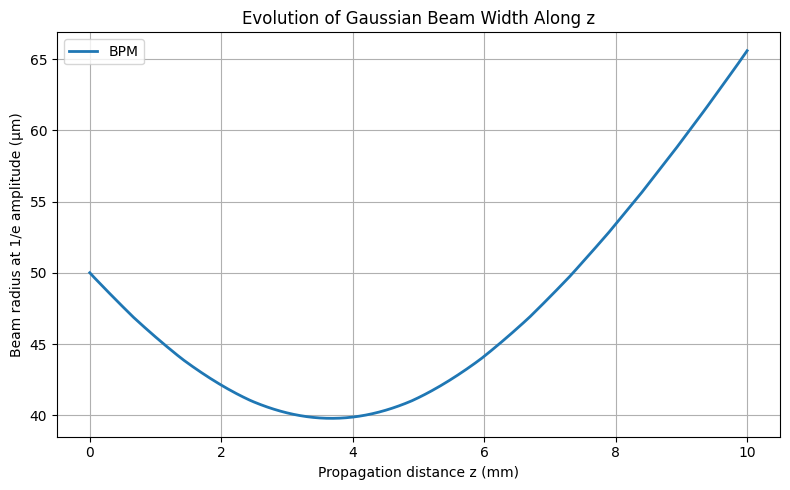

In [31]:
plt.figure(figsize=(8,5))
plt.plot(
    z_positions * 1e3,
    np.asarray(width) * 1e6,
    linewidth = 2,
    label = 'BPM'
)

plt.xlabel("Propagation distance z (mm)")
plt.ylabel("Beam radius at 1/e amplitude (µm)")

plt.title("Evolution of Gaussian Beam Width Along z")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Lets have a look at the input and output fields: 

### 5.- Simulation with Optical device. 

For the simulated optical device a Axicon submerged in a liquid solution was chosen. The objective is recreate the beam radius obtained from the article on the setup showed below. 

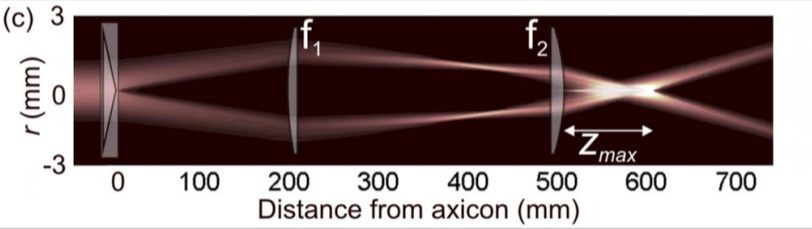

$$
\begin{gathered}
\psi_{\text{axicon}}(x,y) = \psi(x,y,0) \times t_{\text{ax}}(x,y)
\\[0.8em] % Adjust this value (e.g., 0.5em, 1em) for more/less space

\psi_{\mathrm{f_1 in}}=
\mathcal{P}(z=f_1)\{\psi_{\mathrm{axicon}}\} \space , \space \psi_{\mathrm{f_1 out}} = \psi_{\mathrm{f_1 in}} \times t_{f_1}(x,y)
\\[0.8em]

\psi_{\mathrm{f_2 in}}=
\mathcal{P}(z=f_1 + f_2)\{\psi_{\mathrm{f_1 out}}\} \space , \space \psi_{\mathrm{f_2 out}} = \psi_{\mathrm{f_2 out}} \times t_{f_2}(x,y)

\\[0.8em]
\psi_{\mathrm{final}} =
\mathcal{P}(a)\{\psi_{\mathrm{axicon,out}}\}
\end{gathered}
$$

Here, $\mathcal{P}$ represents Fresnel propagation. Now we will begin by coding the lexicon and lenses phase masks functions $t_{\text{ax}}(x,y)$, $t_{f_1}(x,y)$ and $t_{f_2}(x,y)$.

$$
t_{\text{ax}}(x,y) \approx \exp{[i k_0 \gamma (n_{\text{ax}} - n_{\text{PDMS}}) \sqrt{x^2 + y^2}]}
$$

With $\gamma$ being the axicon base angle and $n_{\mathrm{ax}}$ the axicon and $n_{\text{PDMS}}$ the liquid refractive indexes.

The phase masks from the thin lenses as a telescope are given by: 

$$
t_{f_1}(x,y)= \exp\left[-i\frac{k_0}{2f_1}(x^2+y^2)\right], \space \& \space t_{f_2}(x,y)= \exp\left[-i\frac{k_0}{2f_2}(x^2+y^2)\right]
$$

In [ ]:
# Axicon parameters
n_ax = 1.45
n_PDMS = 1.43
gamma_deg = 5.0
gamma = np.deg2rad(gamma_deg)

# Phase mask
phi_axicon = k0 * (n_ax - 1) * (Kx**2 + Ky**2) * np.sin(gamma)

# Equivalent diffractive phase mask
phi_wrapped = np.mod(phi_axicon, 2*np.pi)

t_axicon = np.exp(1j * phi_wrapped)

Now let's combine everything together and simulate the propagation process.

In [14]:
psi = psi_lens.copy()

intensity_ax = np.zeros((N, Nz+1))
width_ax = []
energy_ax = []

snapshots = {}

# Axicon must be placed on a propagation plane
z_axicon = f
ax_index = int(round(z_axicon / dz))
z_axicon_actual = ax_index * dz

if ax_index < 0 or ax_index > Nz:
    raise ValueError("Axicon position must be inside the simulation.")

for iz in range(Nz+1):
    if iz == ax_index:
        psi_axicon_in = psi.copy()

        psi = psi * t_axicon
        
        psi_axicon_out = psi.copy()

        snapshots["After axicon"] = psi.copy()

    # Record intensity and beam width
    intensity_ax[:, iz] = np.abs(psi[:, N//2])**2

    width_ax.append(measure_beam_width(psi))
    energy_ax.append(calculate_energy(psi))

    # Save selected transverse planes
    if iz in [
        0,
        ax_index,
        int(0.6*Nz),
        int(0.8*Nz),
        Nz
    ]:
        snapshots[f"z = {z_positions[iz]*1e3:.1f} mm"] = psi.copy()

    if iz < Nz:
        psi = propagate_step(psi)

psi_final_ax = psi.copy()



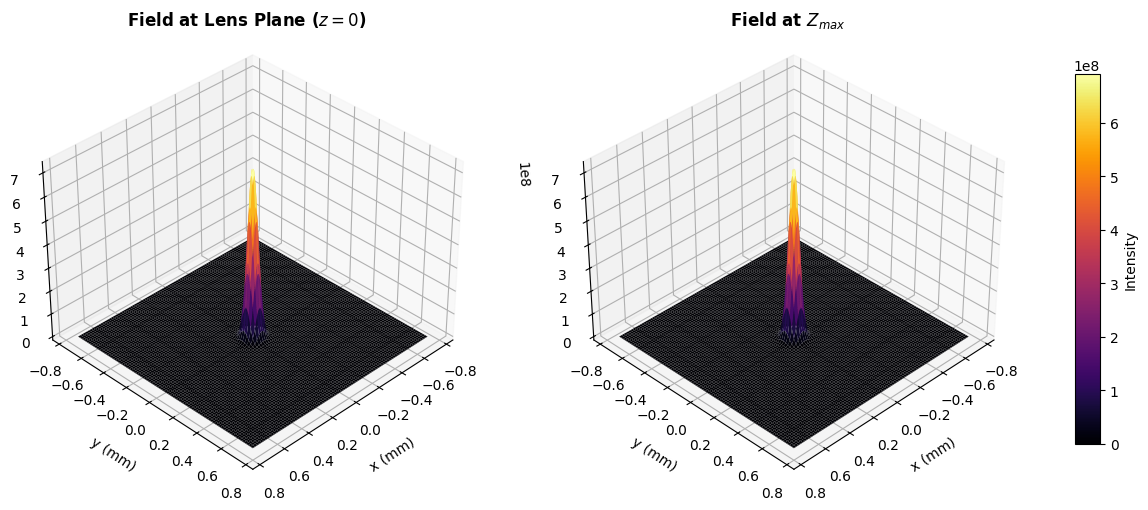

In [15]:
# Create a side-by-side figure with 3D projections
fig = plt.figure(figsize=(16, 8))

# Adjust step for smooth rendering vs performance balance
step = max(1, N // 80)

# --- Subplot 1: Lens / Initial Plane ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
intensity_initial = np.abs(psi_axicon_in)**2  # Plotting physical intensity

surf1 = ax1.plot_surface(X * 1e3, Y * 1e3, intensity_initial, 
                          cmap='inferno', edgecolor='none', 
                          rstride=step, cstride=step, 
                          antialiased=True, shade=True)

ax1.set_title("Field at Lens Plane ($z = 0$)", fontsize=12, fontweight='bold')
ax1.set_xlabel("x (mm)", labelpad=8)
ax1.set_ylabel("y (mm)", labelpad=8)
ax1.view_init(elev=35, azim=45)  # Optimal viewing angle

# --- Subplot 2: Final Propagated Plane ($Z_{max}$) ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
intensity_final = np.abs(psi_axicon_out)**2  # Assuming psi_final is your final field variable

surf2 = ax2.plot_surface(X * 1e3, Y * 1e3, intensity_final, 
                          cmap='inferno', edgecolor='none', 
                          rstride=step, cstride=step, 
                          antialiased=True, shade=True)

ax2.set_title(f"Field at $Z_{{max}}$", fontsize=12, fontweight='bold')
ax2.set_xlabel("x (mm)", labelpad=8)
ax2.set_ylabel("y (mm)", labelpad=8)
ax2.view_init(elev=35, azim=45)

# Add a clean shared colorbar
fig.colorbar(surf2, ax=[ax1, ax2], shrink=0.6, aspect=15, label='Intensity')

plt.show()

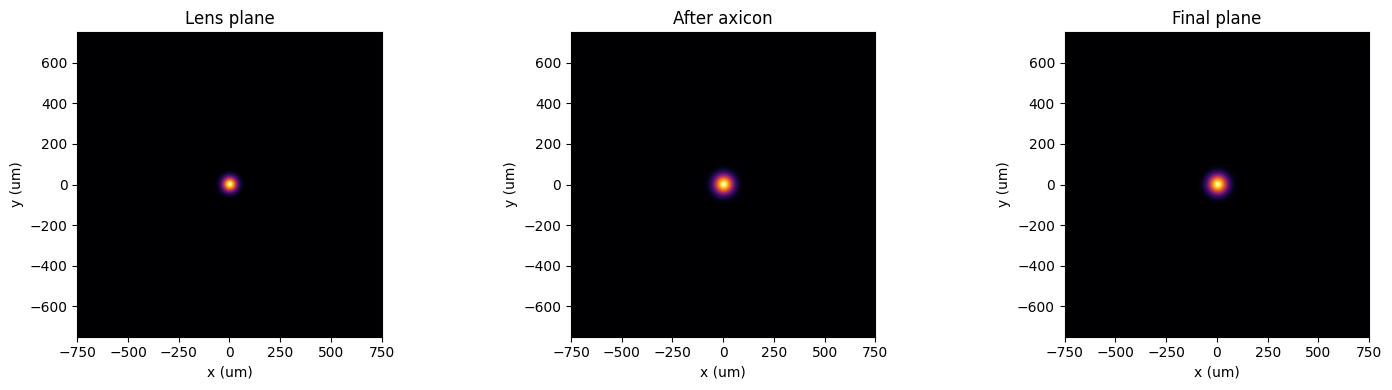

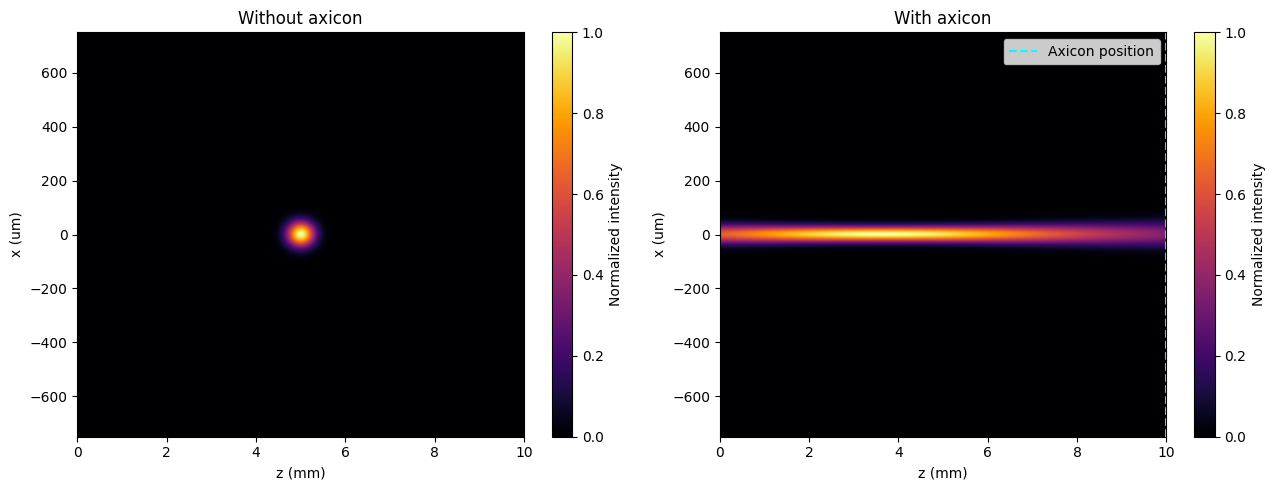

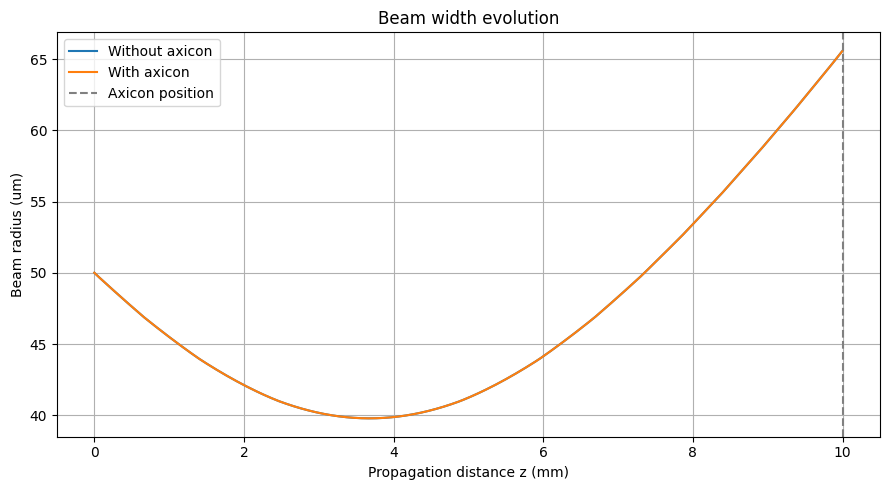

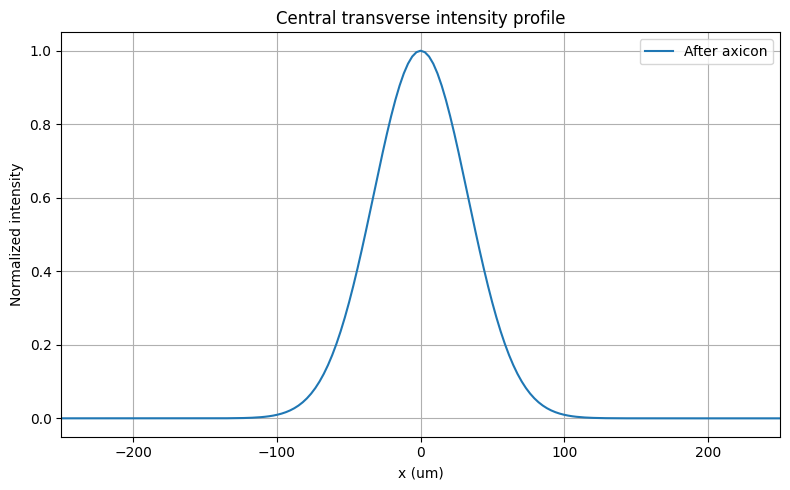

In [ ]:
# ============================================================
# TRANSVERSE INTENSITY DISTRIBUTIONS
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

planes = [
    ("Lens plane", psi_lens),
    ("After axicon", psi_axicon_out),
    ("Final plane", psi_final_ax)
]

for ax, (title, field) in zip(axes, planes):

    intensity = np.abs(field)**2

    ax.imshow(
        intensity / np.max(intensity),
        extent=[-L/2*1e6, L/2*1e6,
                -L/2*1e6, L/2*1e6],
        origin="lower",
        cmap="inferno",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.set_xlabel("x (um)")
    ax.set_ylabel("y (um)")

plt.tight_layout()
plt.show()

# ============================================================
# LONGITUDINAL INTENSITY DISTRIBUTION

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

extent = [
    0,
    Z_max*1e3,
    -L/2*1e6,
    L/2*1e6
]

im1 = axes[0].imshow(
    intensity / np.max(intensity),
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="inferno"
)

axes[0].set_title("Without axicon")
axes[0].set_xlabel("z (mm)")
axes[0].set_ylabel("x (um)")
plt.colorbar(im1, ax=axes[0], label="Normalized intensity")

im2 = axes[1].imshow(
    intensity_ax / np.max(intensity_ax),
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="inferno"
)

axes[1].axvline(
    z_axicon_actual*1e3,
    color="cyan",
    linestyle="--",
    label="Axicon position"
)

axes[1].set_title("With axicon")
axes[1].set_xlabel("z (mm)")
axes[1].set_ylabel("x (um)")
axes[1].legend()

plt.colorbar(im2, ax=axes[1], label="Normalized intensity")

plt.tight_layout()
plt.show()

# ============================================================
# BEAM WIDTH EVOLUTION

plt.figure(figsize=(9, 5))

plt.plot(
    z_positions*1e3,
    np.array(width)*1e6,
    label="Without axicon"
)

plt.plot(
    z_positions*1e3,
    np.array(width_ax)*1e6,
    label="With axicon"
)

plt.axvline(
    z_axicon_actual*1e3,
    color="gray",
    linestyle="--",
    label="Axicon position"
)

plt.xlabel("Propagation distance z (mm)")
plt.ylabel("Beam radius (um)")
plt.title("Beam width evolution")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# RADIAL INTENSITY PROFILE AFTER AXICON

center = N//2

plt.figure(figsize=(8, 5))

for label, field in snapshots.items():

    if "After axicon" in label:
        profile = np.abs(field[center, :])**2
        profile /= np.max(profile)

        plt.plot(
            x*1e6,
            profile,
            label=label
        )

plt.xlabel("x (um)")
plt.ylabel("Normalized intensity")
plt.title("Central transverse intensity profile")
plt.xlim(-250, 250)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()
